# Lorenz system identification with SINDy and LASSO

This notebook identifies the three coupled Lorenz equations from sampled data. It uses the numerical setup in Brunton and Kutz, *Data-Driven Science and Engineering*, 2nd ed., Chapter 7, Code 7.5: $\sigma=10$, $\rho=28$, $\beta=8/3$, initial state $(-8,8,27)$, $\Delta t=0.01$, final time 50, cubic polynomial features, and coefficient cutoff 0.025.

**Method difference:** Code 7.5 uses sequential thresholded least squares and calculates derivatives with the known governing equations. Here LASSO selects candidate terms; the 0.025 cutoff removes negligible coefficients; least squares refits the selected terms. Derivatives are estimated from the sampled states, so the true equations are used for data generation and evaluation but not as regression targets. The LASSO penalty $\alpha=10^{-4}$ is distinct from Code 7.5's 0.025 cutoff.

Sources: [Cambridge University Press, Chapter 7](https://www.cambridge.org/highereducation/books/data-driven-science-and-engineering/6F9A730B7A9A9F43F68CF21A24BEC339/data-driven-dynamical-systems/C9DBB0A34A6A4798AB1D90A90302510F); [authors' Code 7.5 companion example](https://github.com/dynamicslab/databook_matlab/blob/master/CH07/CH07_SEC03_SINDY_Lorenz_production.m).

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LassoLars
from sklearn.metrics import r2_score

plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True})
print("Dependencies: numpy, scipy, scikit-learn, matplotlib")

Dependencies: numpy, scipy, scikit-learn, matplotlib


## 1. Generate sampled states

The reference equations are
$$\dot x=\sigma(y-x),\qquad \dot y=x(\rho-z)-y,\qquad \dot z=xy-\beta z.$$
The resulting data matrix $X$ has one row per time sample and columns $x$, $y$, and $z$. This is a clean simulated-data example; real measured states can replace the simulation.

In [23]:
sigma, rho, beta = 10.0, 28.0, 8.0 / 3.0
x0 = np.array([-8.0, 8.0, 27.0])
dt = 0.01
t = np.arange(0.01, 50.0 + dt / 2, dt)
degree = 3
coefficient_cutoff = 0.025
lasso_alpha = 1e-4

def lorenz_rhs(time, state):
    x, y, z = state
    return [sigma * (y - x), x * (rho - z) - y, x * y - beta * z]

def simulate(rhs, times, initial_state):
    result = solve_ivp(rhs, (times[0], times[-1]), initial_state,
                       t_eval=times, rtol=1e-12, atol=1e-12)
    return result.y.T

X = simulate(lorenz_rhs, t, x0)
print(f"X shape: {X.shape}; parameters: σ={sigma:g}, ρ={rho:g}, β={beta:.6f}")

X shape: (5000, 3); parameters: σ=10, ρ=28, β=2.666667


## 2. Estimate derivatives from data

A fourth-order centered difference estimates $\dot X$. We drop two samples from each end to use the five-point stencil. The true right-hand side is not used in this fit.

$$\dot X_i \approx
\frac{X_{i-2}-8X_{i-1}+8X_{i+1}-X_{i+2}}{12\Delta t}.$$


In [ ]:
X_fit = X[2:-2]
dXdt_fit = (X[:-4] - 8 * X[1:-3] + 8 * X[3:-1] - X[4:]) / (12 * dt)
print("X_fit:", X_fit.shape, "dXdt_fit:", dXdt_fit.shape)

X_fit: (4996, 3) dXdt_fit: (4996, 3)


## 3. Candidate functions of the full state

The cubic library has 20 columns: $1$, the three states, all quadratic terms including $xy$ and $xz$, and all cubic terms. At each time it evaluates the **full state vector**, permitting one state to influence another. In the book's Eq. 7.48, $\dot X\approx\Theta(X)\Xi$ has dimensions $(m\times3)\approx(m\times20)(20\times3)$.

In [ ]:
library = PolynomialFeatures(degree=degree, include_bias=True)
Theta = library.fit_transform(X_fit)
feature_names = library.get_feature_names_out(["x", "y", "z"])
assert Theta.shape == (len(X_fit), 20)
print("Θ(X) shape:", Theta.shape)
print("Features:", ", ".join(feature_names))

Θ(X) shape: (4996, 20)
Features: 1, x, y, z, x^2, x y, x z, y^2, y z, z^2, x^3, x^2 y, x^2 z, x y^2, x y z, x z^2, y^3, y^2 z, y z^2, z^3


## 4. Fit the sparse coefficient matrix

Library columns are scaled to unit root-mean-square size before LASSO. LassoLars solves the $L_1$-regularized LASSO problem. After selecting terms with the Code 7.5 cutoff of 0.025 in original feature units, least squares removes LASSO shrinkage from the retained coefficients.

In [ ]:
scale = np.sqrt(np.mean(Theta**2, axis=0))
Theta_scaled = Theta / scale
Xi_lasso = np.zeros((Theta.shape[1], 3))
Xi = np.zeros_like(Xi_lasso)

for j in range(3):
    model = LassoLars(alpha=lasso_alpha, fit_intercept=False)
    model.fit(Theta_scaled, dXdt_fit[:, j])
    Xi_lasso[:, j] = model.coef_ / scale
    keep = np.abs(Xi_lasso[:, j]) >= coefficient_cutoff
    Xi[keep, j] = np.linalg.lstsq(Theta[:, keep], dXdt_fit[:, j],
                                 rcond=None)[0]

print("Ξ shape:", Xi.shape)
print("Selected coefficients:", np.count_nonzero(Xi), "of", Xi.size)
print("Training derivative RMSE:",
      f"{np.sqrt(np.mean((Theta @ Xi - dXdt_fit)**2)):.6f}")

Ξ shape: (20, 3)
Selected coefficients: 7 of 60
Training derivative RMSE: 0.005298


In [ ]:
def equation_string(coefficients, names):
    parts = []
    for value, name in zip(coefficients, names):
        if value != 0:
            variable = "" if name == "1" else name.replace(" ", "·")
            parts.append(f"{value:+.6f}{variable}")
    return " ".join(parts).lstrip("+")

for j, name in enumerate(("x", "y", "z")):
    print(f"d{name}/dt = {equation_string(Xi[:, j], feature_names)}")
print("\nReference: dx/dt = -10x + 10y")
print("           dy/dt = 28x - y - xz")
print("           dz/dt = xy - (8/3)z")

dx/dt = -9.999873x +9.999873y
dy/dt = 27.997754x -0.999486y -0.999941x·z
dz/dt = -2.666603z +0.999976x·y

Reference: dx/dt = -10x + 10y
           dy/dt = 28x - y - xz
           dz/dt = xy - (8/3)z


## 5. Evaluate on unseen states

We simulate a new trajectory from $(5,5,25)$ and compare its actual derivatives with the learned vector field. The reference equations are evaluated **only after fitting**, for this accuracy check.

In [ ]:
test_x0 = np.array([5.0, 5.0, 25.0])
t_test = np.arange(0.01, 12.0 + dt / 2, dt)
X_test = simulate(lorenz_rhs, t_test, test_x0)
dXdt_true_test = np.array([lorenz_rhs(0.0, state) for state in X_test])
dXdt_pred_test = library.transform(X_test) @ Xi
rmse_by_state = np.sqrt(np.mean((dXdt_pred_test - dXdt_true_test)**2, axis=0))
r2_by_state = r2_score(dXdt_true_test, dXdt_pred_test,
                       multioutput="raw_values")
for name, rmse, r2 in zip(("x", "y", "z"), rmse_by_state, r2_by_state):
    print(f"d{name}/dt: unseen-state RMSE={rmse:.6f}; R²={r2:.9f}")

dx/dt: unseen-state RMSE=0.000495; R²=1.000000000
dy/dt: unseen-state RMSE=0.002463; R²=0.999999998
dz/dt: unseen-state RMSE=0.001735; R²=0.999999999


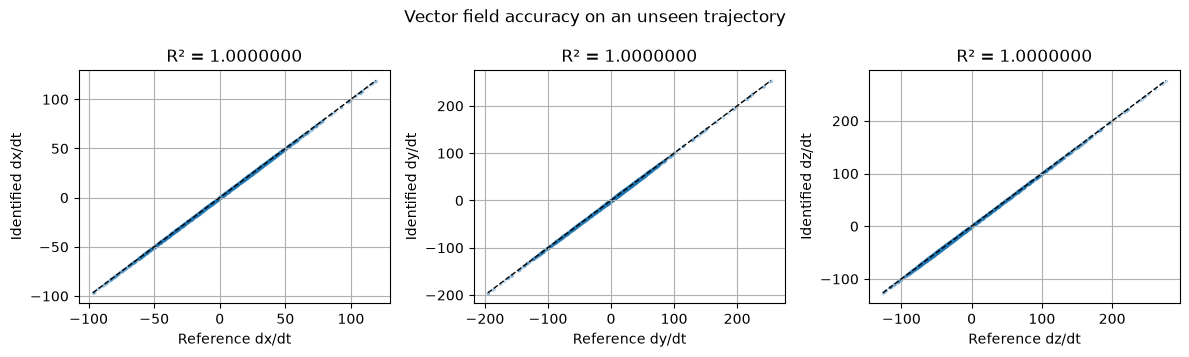

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for j, ax in enumerate(axes):
    ax.scatter(dXdt_true_test[:, j], dXdt_pred_test[:, j], s=3, alpha=0.2)
    lo = min(dXdt_true_test[:, j].min(), dXdt_pred_test[:, j].min())
    hi = max(dXdt_true_test[:, j].max(), dXdt_pred_test[:, j].max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set(xlabel=f"Reference d{'xyz'[j]}/dt",
           ylabel=f"Identified d{'xyz'[j]}/dt",
           title=f"R² = {r2_by_state[j]:.7f}")
fig.suptitle("Vector field accuracy on an unseen trajectory")
fig.tight_layout()
plt.show()

## 6. Compare trajectories and attractors

We integrate the identified equations. The five-unit comparison shows short-horizon agreement from the unseen initial state. The 50-unit plots compare the geometry of the chaotic attractor. Long-run pointwise separation is expected in a chaotic system even for very small coefficient errors.

Unseen five-unit trajectory RMSE: 0.012491


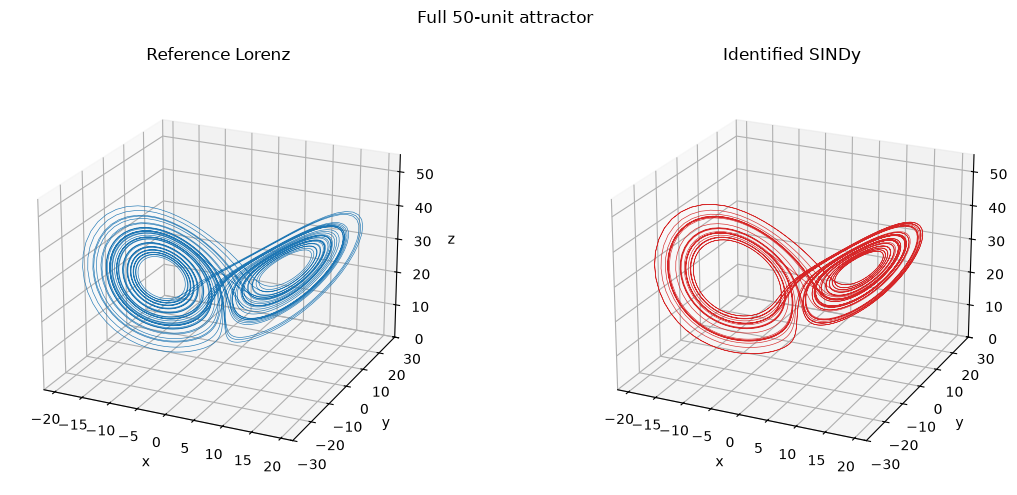

In [ ]:
def identified_rhs(time, state):
    return library.transform(np.asarray(state).reshape(1, -1))[0] @ Xi

X_identified = simulate(identified_rhs, t, x0)
X_test_identified = simulate(identified_rhs, t_test, test_x0)
short = t_test <= 5.01
short_rmse = np.sqrt(np.mean((X_test_identified[short] - X_test[short])**2))
print(f"Unseen five-unit trajectory RMSE: {short_rmse:.6f}")

fig = plt.figure(figsize=(12, 5))
for k, (trajectory, title) in enumerate(((X, "Reference Lorenz"),
                                         (X_identified, "Identified SINDy")), 1):
    ax = fig.add_subplot(1, 2, k, projection="3d")
    ax.plot(*trajectory.T, lw=0.45, color="C0" if k == 1 else "C3")
    ax.set(xlabel="x", ylabel="y", zlabel="z", title=title,
           xlim=(-22, 22), ylim=(-30, 30), zlim=(0, 55))
    ax.view_init(elev=22, azim=-65)
fig.suptitle("Full 50-unit attractor")
fig.tight_layout()
plt.show()

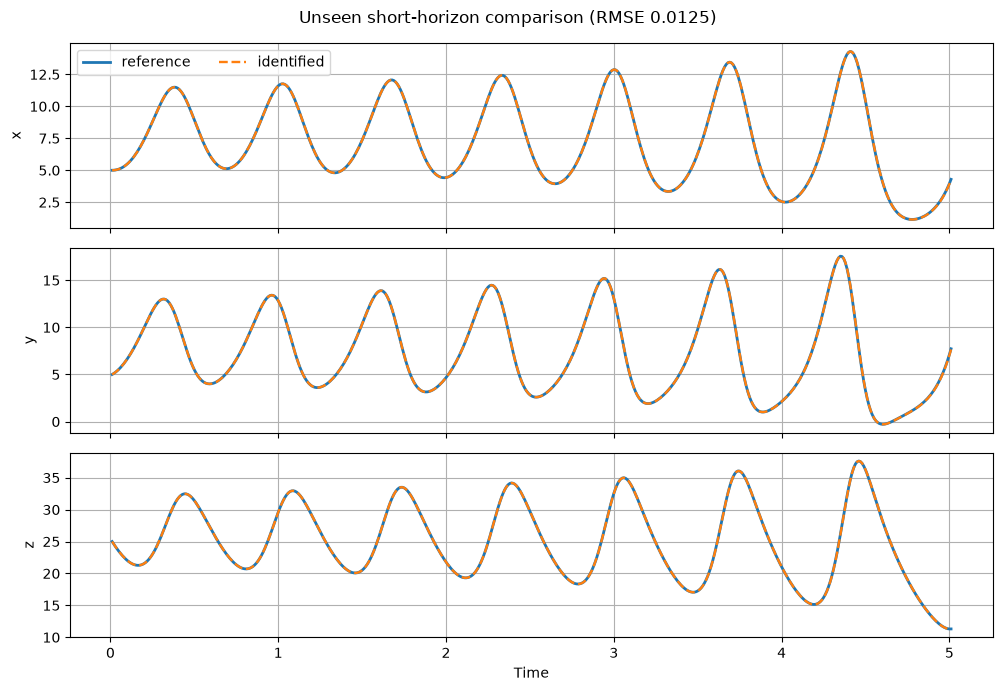

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for j, ax in enumerate(axes):
    ax.plot(t_test[short], X_test[short, j], lw=2, label="reference")
    ax.plot(t_test[short], X_test_identified[short, j], "--",
            lw=1.7, label="identified")
    ax.set_ylabel("xyz"[j])
axes[0].legend(ncol=2)
axes[-1].set_xlabel("Time")
fig.suptitle(f"Unseen short-horizon comparison (RMSE {short_rmse:.4f})")
fig.tight_layout()
plt.show()